# 🚀 NB08: Intermediate Representations and Static Analysis

#### Nuno Macedo
Universidade do Minho


## Goals

By the end of this class, the student should be able to:

  - Understand the role of intermediate representations in language processing

  - Identify different kinds of IRs and understand how they support different processing tasks, such as translation and static analysis

  - Understand how to extract analysis-oriented graph representations from programs

  - Use these representations to reason about program properties and perform basic analyses

  - Understand the principles of static program analysis

# 8.1 Intermediate Representations

## Beyond tree representations

- After parsing and semantic elaboration, we obtain an **annotated syntax tree** that reflects the structure and meaning of the source program

- This representation is useful for many tasks, but it is not always the most convenient one for further processing

- Different processing tasks may require different views of the same program:
  - **Translation**: may require a sequence of simpler operations in the target language
  - **Optimization**: may need to identify redundant or equivalent computations
  - **Static analysis**: may need to reason about control flow and data dependencies

- An **Intermediate Representation** (IR) is a representation of a program used between its original representation and a subsequent processing task

- IRs make selected aspects of a program's structure or semantics **explicit**, making particular analyses and transformations easier to express

- Different IRs emphasize different relationships in the program

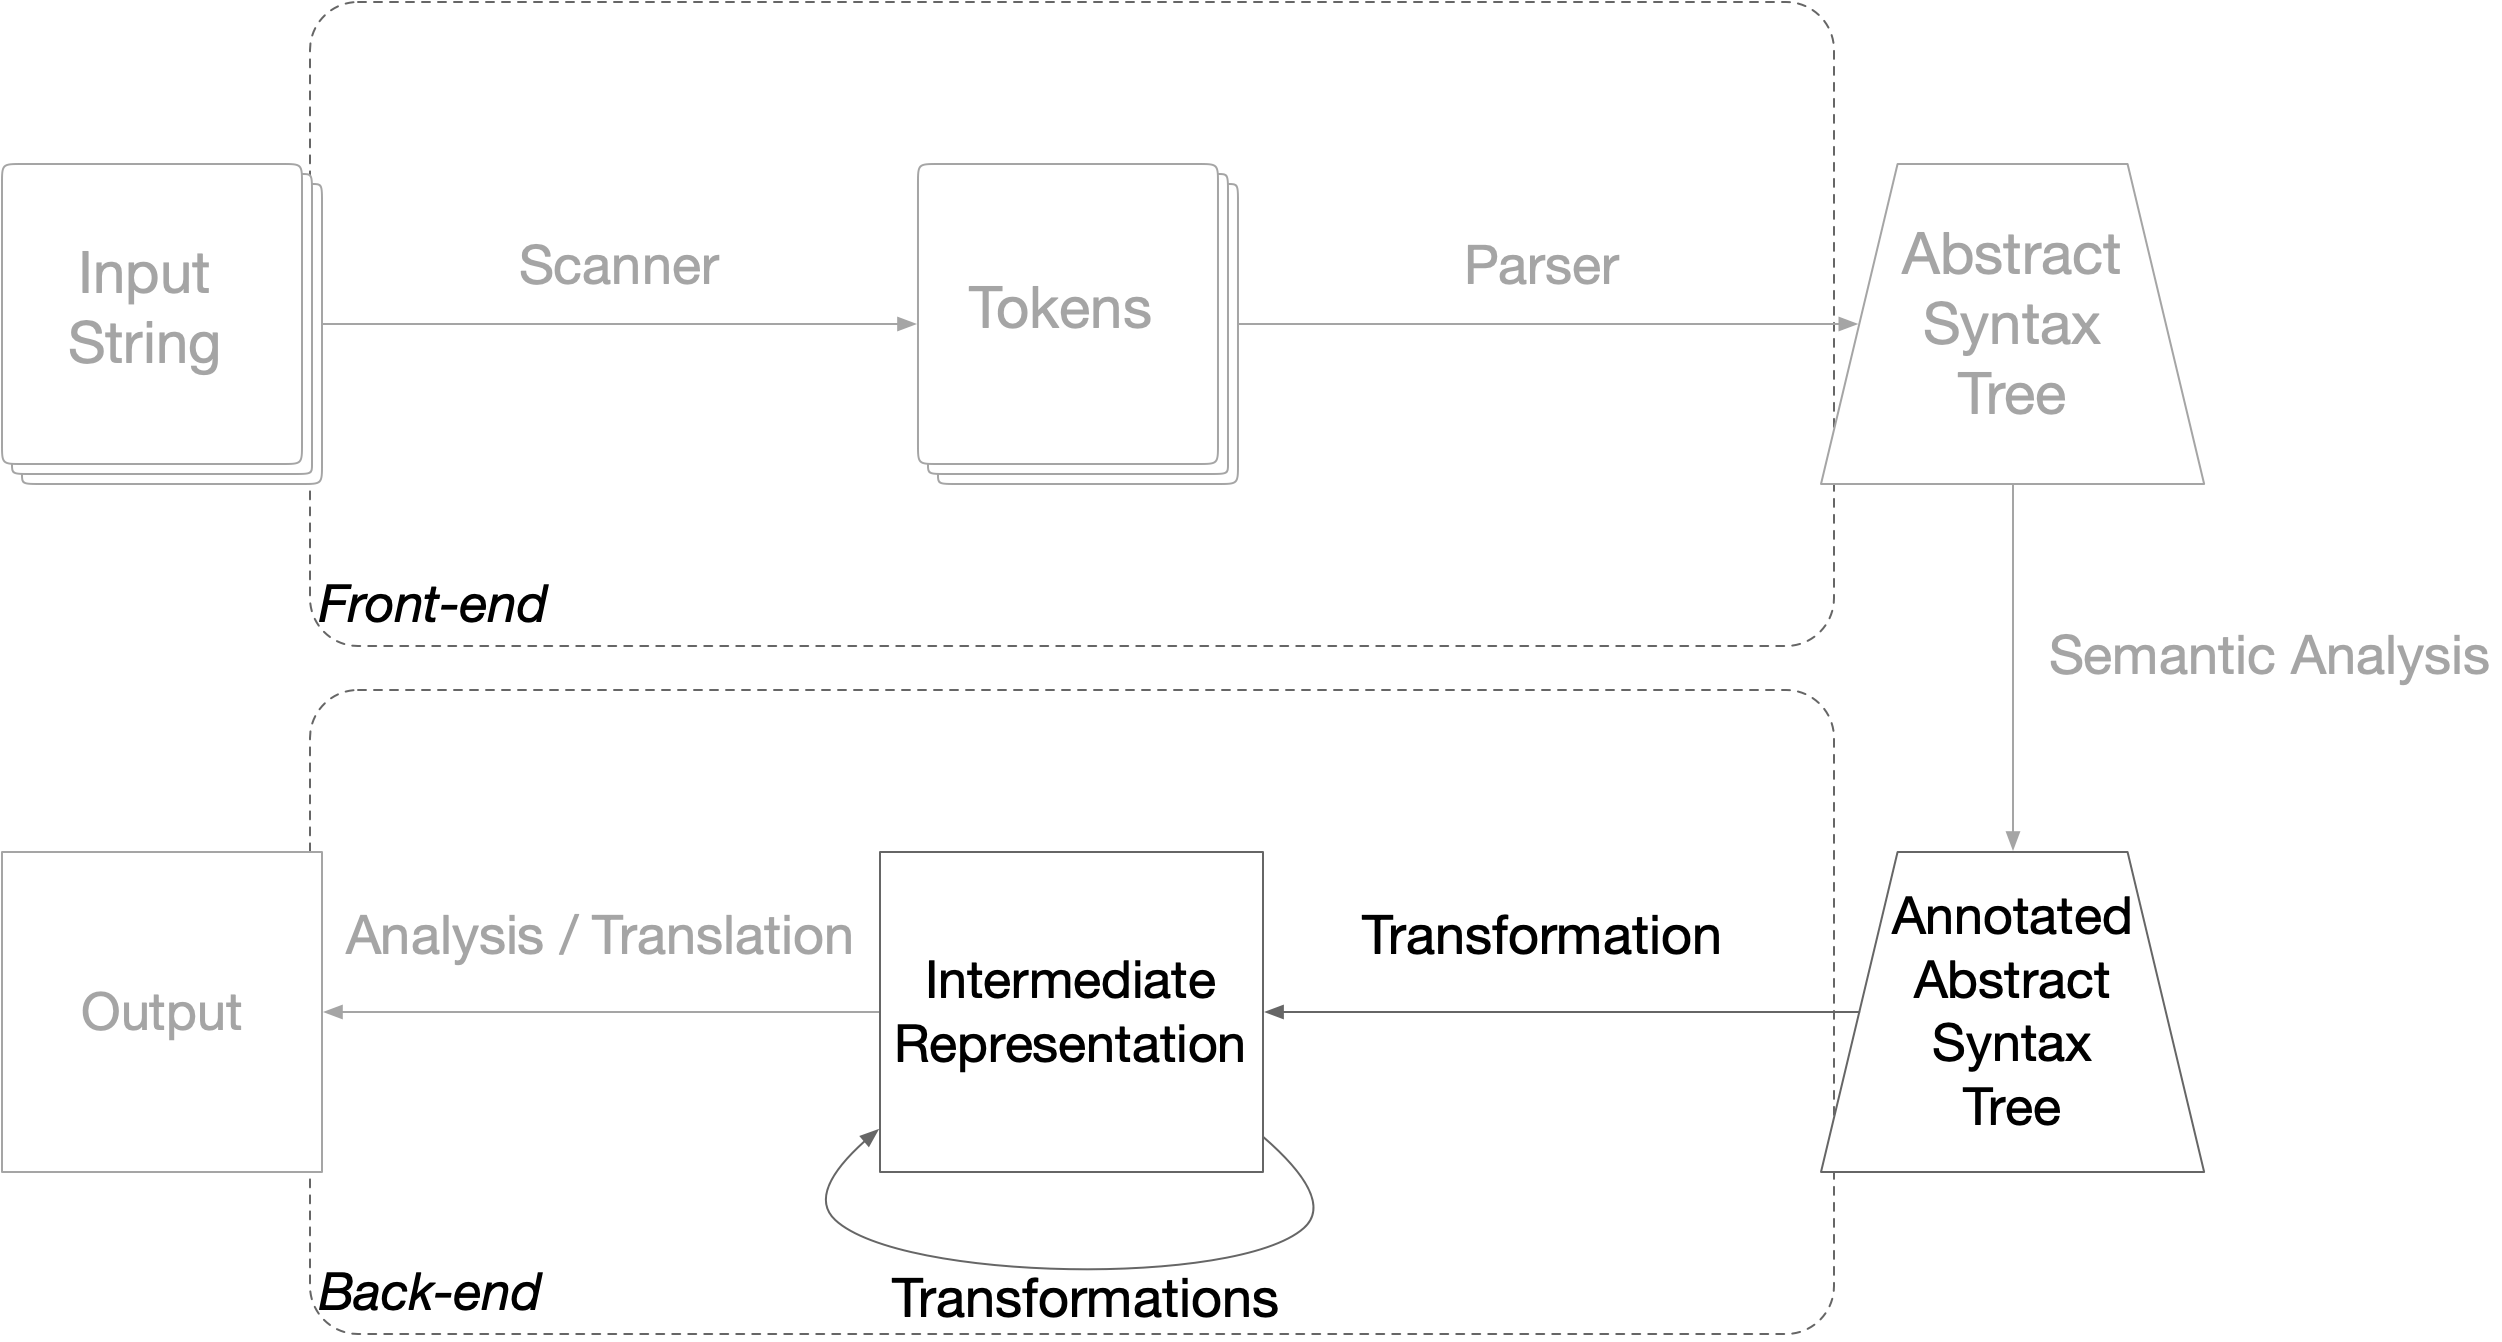


## Intermediate representations

- An IR is a representation of a program designed to support a particular language-processing task, such as translation, optimization or static analysis

- An IR should provide properties that make the intended processing convenient:
  - **Semantics-preserving**: retain the meaning of the program, or the semantic properties relevant to the task
  - **Abstract**: remove or simplify details that are not relevant to the intended processing
  - **Target-independent**: when appropriate, avoid depending on a particular output language or architecture
  - **Modular**: provide a common representation that can be reused by different processing tasks

- These properties are design goals rather than requirements that every IR must satisfy in the same way

- In practice, language-processing pipelines often use a **chain of IRs**, each tailored to a particular task or processing phase

- An IR may itself be another **computer language**, with its own syntax and semantics, but it may also be represented internally as a data structure


## Advantages of using an IR

- **Simplify subsequent processing** by making relevant program structure and semantic information explicit

- **Decouple** the source language from subsequent processing:
  - the backend can operate on the IR rather than directly on the source representation
  - changes to the source language need not require changes to every backend component, provided the IR remains compatible

- **Encourage reuse**: multiple analyses and transformations can operate on the same IR

- **Provide a common platform** for different processing tasks, such as translation, optimization and static analysis


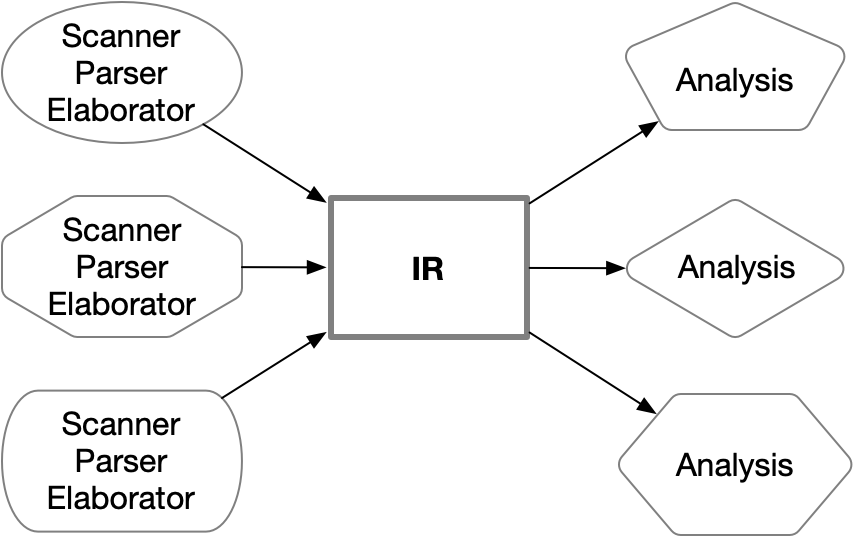

## Types of IRs

- Different language-processing tasks may require different representations of the same program

- The choice of IR depends on:
  - the information that needs to be made explicit
  - the processing that needs to be performed
  - the form of the desired output

- IRs may take different forms, for example:
  - **Linear representations**, organized as sequences of operations, can make the order of computations explicit
  - **Tree representations** can make hierarchical structure and relationships between operations explicit
  - **Graph representations** can make relationships such as control flow or data dependencies explicit

- These representations support different processing tasks:
  - a **translation** task may use a representation that facilitates mapping source constructs to constructs in another language
  - a **code-generation** task may use a representation that makes low-level operations and their execution order explicit
  - a **static analysis** task may use a representation that makes control flow or data dependencies explicit

- The same program may therefore be represented in different ways, depending on the intended processing task

### Code generation IRs

- Some IRs are designed to facilitate the translation of a program into another representation or target language

- **Linear IRs**
  - Examples: Three-Address Code (TAC) or Quadruples
  - Each instruction performs a simple operation on a small number of operands
  - The sequence makes the order of operations explicit

- **Directed Acyclic Graphs (DAGs)**
  - Capture dependencies between expressions
  - Can make redundant computations explicit, supporting common subexpression elimination

- **Static Single Assignment (SSA)**
  - Each variable is assigned exactly once, with new versions introduced for subsequent assignments
  - Makes data dependencies explicit, supporting optimization and other processing tasks

- **Low-level IRs**
  - Examples: LLVM IR, JVM bytecode, WebAssembly
  - Represent operations at a lower level of abstraction
  - Can serve as a common basis for further transformation and code generation

### ✏️ C code compilation pipeline

- The following example illustrates how the same program can be represented in different ways during a compilation pipeline

- Each representation makes certain aspects of the program more explicit, supporting different processing tasks

- Source code, textual representation
  ```c
  x = 10;
  y = x + 100;
  if (x < 200)
      x = x * 2;
  return x;
  ```

- AST, hierarchical tree, encodes syntax and operator precedence
  ```
  Program
  ├── Assign
  │     ├── Var("x")
  │     └── Int(10)
  ├── Assign
  │     ├── Var("y")
  │     └── Add
  │          ├── Var("x")
  │          └── Int(100)
  ├── If
  │     ├── Cond: Lt
  │     │     ├── Var("x")
  │     │     └── Int(200)
  │     └── Then:
  │           └── Assign
  │                ├── Var("x")
  │                └── Mul
  │                     ├── Var("x")
  │                     └── Int(2)
  └── Return
        └── Var("x")
  ```

- TAC, linear instructions, explicit labels and jumps for control transfers
  ```
  1: x = 10
  2: y = x + 100
  3: if (x < 200) goto L1
  4: goto L2
  L1:
  5: x = x * 2
  6: goto L3
  L2:
  7: goto L3
  L3:
  8: return x
  ```

- SSA, versioned variables, simplifies data-flow reasoning
  ```
  x₁ = 10
  y₁ = x₁ + 100
  if (x₁ < 200) goto L1 else goto L2

  L1:
  x₂ = x₁ * 2
  goto L3

  L2:
  goto L3

  L3:
  x₃ = φ(x₁, x₂)
  return x₃
  ```

- LLVM IR, typed, low-level, portable and optimizable
  ```
  entry:
    %x1 = add i32 0, 10
    %y1 = add i32 %x1, 100
    %cmp = icmp slt i32 %x1, 200
    br i1 %cmp, label %then, label %end

  then:
    %x2 = mul i32 %x1, 2
    br label %end

  end:
    %x3 = phi i32 [%x1, %entry], [%x2, %then]
    ret i32 %x3
  ```

### Translation-oriented IRs

- Some IRs are designed to support the translation of a program from one language into another

- **Abstract Syntax Trees (ASTs)**
  - Represent the hierarchical structure of a program, independently of its concrete syntax
  - Can be transformed to represent equivalent constructs in the target language
  - For example, an AST transformation can replace a construct from the source language with an equivalent combination of target-language constructs

- **Linear representations**
  - Represent a program as a sequence of simpler operations
  - Can make it easier to translate complex source constructs into simpler target constructs

- These representations allow translation to be organized as separate steps: constructing an intermediate representation, transforming it, and generating the target code

### ✏️ Source-to-source translation

- Consider the parenthesized language we've seen before, and let's try to translate it into Python

- Source program
  ```lisp
  (decl x int)
  (set x (+ 10 20))
  (print x)
  ```

- After parsing and semantic analysis, we obtain the annotated AST

  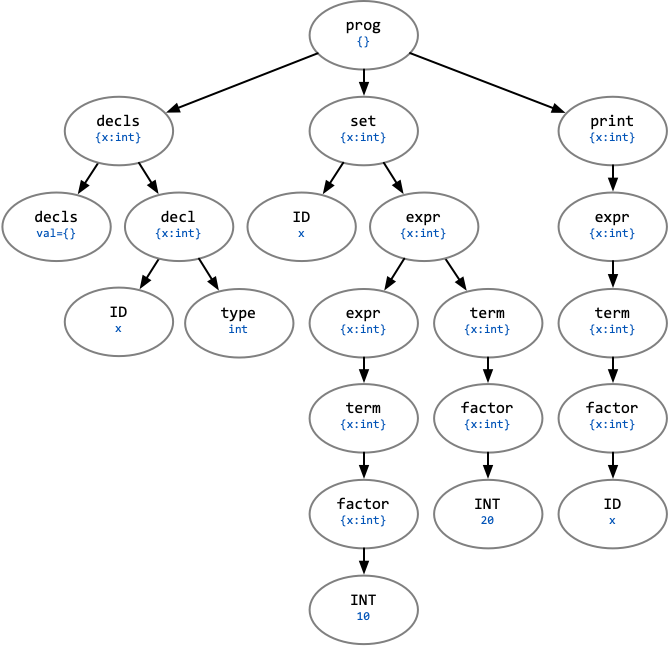

- We can translate the AST by mapping:
  - `decl` → no target construct
  - `set` → Python assignment (`assign`)
  - `print` → Python function call (`call`)
  - `(+ 10 20)` → Python addition expression

- Resulting Python AST

  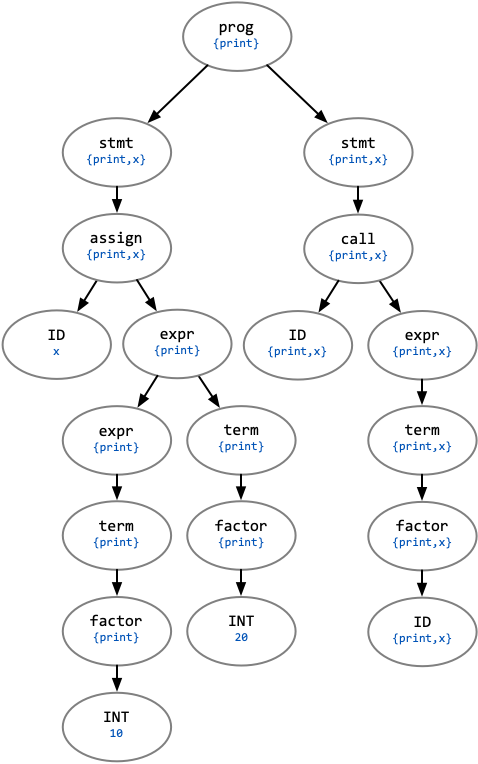

- Corresponding to the target program
  ```python
  x = 10 + 20
  print(x)
  ```

### Analysis-oriented IRs

- Some IRs are designed to make properties of a program explicit, supporting different kinds of static analysis

- **Control-Flow Graphs (CFGs)** represent the possible flow of execution between basic blocks
  - Useful for reasoning about reachability, loops and execution paths

- **Data-Flow Graphs (DFGs)** represent dependencies between operations and the values they use or produce
  - Useful for reasoning about how values are computed and propagated

- **Program Dependence Graphs (PDGs)** represent both control and data dependencies
  - Useful for understanding how statements depend on one another, for example in program slicing

- These representations provide different views of a program, each emphasizing relationships relevant to particular analyses




### ✏️ C code graph extraction

- We can derive different representations from a program's AST, each exposing information relevant to a particular kind of analysis

- The AST captures the hierarchical structure of the program, while graph representations make control-flow and data dependencies explicit

- Source code, textual representation
  ```c
  x = 10;
  y = x + 5;
  if (y > 12)
      z = x + y;
  else
      z = y - 2;
  return z;
  ```

- AST, syntax and hierarchical representation

  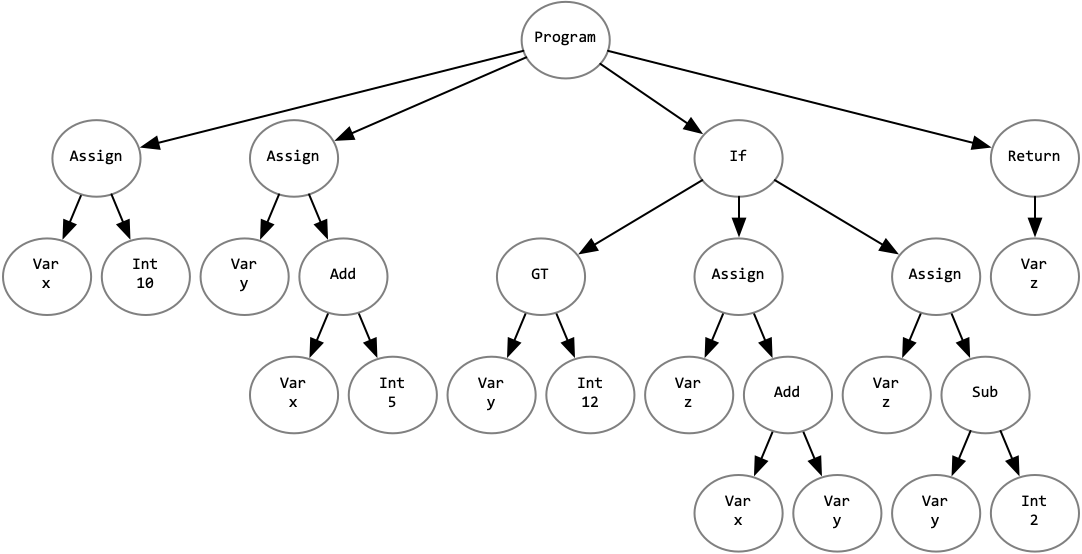


- Control-flow graph, possible execution paths

  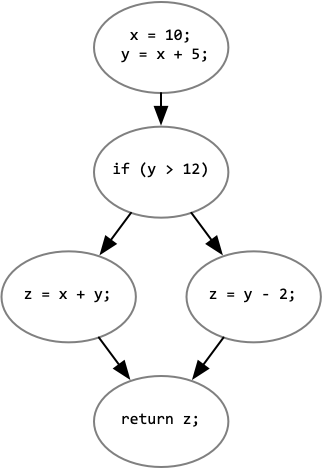


- Data-flow graphs, introduce data dependencies


  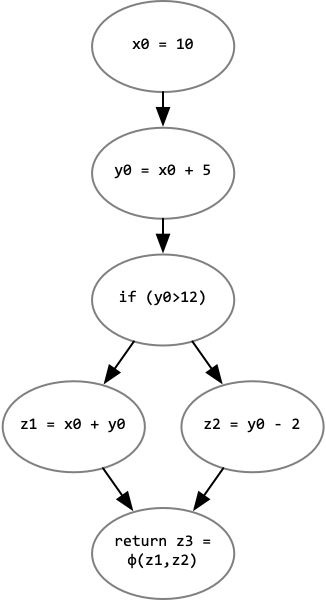

# 8.2 Extracting IRs for Analysis

## Control-flow graphs

- A **Control-Flow Graph (CFG)** represents the possible flow of execution through a program

- It makes explicit:
  - where execution can branch
  - where different execution paths can merge
  - where execution can repeat

- CFGs are a fundamental representation in program analysis:
  - many static analyses are performed over CFGs
  - other representations, such as Program Dependence Graphs (PDGs), combine control and data dependencies

- A CFG allows us to inspect and reason about the possible execution paths of a program, and to answer simple questions before applying more advanced static analysis techniques

- We will focus on **intra-procedural CFGs**, representing the control flow within a single function

### CFG definition and concepts

- A **Control-Flow Graph** is a directed graph where:
  - **Nodes** represent basic blocks
  - **Edges** represent possible transfers of control between basic blocks

- A **basic block** is a maximal sequence of consecutive instructions with:
  - a single entry point
  - a single exit point
  - no branching or jumps except possibly at the end of the block

- Additional terminology:
  - **Entry**: the block where execution begins
  - **Exit**: a block where execution leaves the function
  - **Successor**: a block that may execute immediately after another block
  - **Predecessor**: a block that may transfer control to another block

- To construct a CFG:
  - Partition the code into basic blocks
  - Identify the possible control transfers between blocks
  - Represent these transfers as directed edges

### ✏️ Identifying basic blocks

- Consider the following C program
  ```c
  int y = 0;
  if (x > 0) {
      y = y + 1;
  } else {
      y = y - 1;
  }
  while (y < 5) {
      y = y + 2;
  }
  return y;
  ```

- We can partition the program into **basic blocks**:
  - maximal sequences of instructions with a single entry and a single exit

  ```c
  B1: y = 0
      if (x > 0) goto B2 else B3

  B2: y = y + 1
      goto B4

  B3: y = y - 1
      goto B4

  B4: while (y < 5) goto B5 else B6

  B5: y = y + 2
      goto B4

  B6: return y
  ```

- The conditional instruction terminates `B1` because it determines which block executes next

- `B2` and `B3` are separate blocks because they correspond to different branches of the conditional

- Both branches continue at `B4`

- `B4` either moves to `B5` (the loop body) or skips to `B6`

- `B5` has a back edge, introducing a cycle in the graph

- `B6` is an exit block

### ✏️ Constructing a CFG

- Having identified the basic blocks, we can now determine the possible transfers of control between them


- The edges of the CFG represent the possible transfers of control between basic blocks

  ```
  B1 → B2 and B1 → B3
  B2 → B4
  B3 → B4
  B4 → B5
  B5 → B4
  B4 → B6
  ```

- The resulting CFG is:

  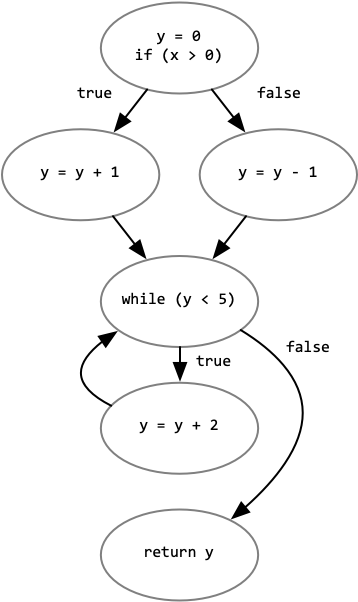

## Using a CFG

- Once constructed, a CFG provides a representation that we can inspect to reason about the possible execution of a program

- By examining its nodes and edges, we can answer questions such as:
  - Which basic blocks are reachable from the entry block?
  - Which blocks may execute immediately before or after a given block?
  - What possible execution paths exist?
  - Does the graph contain loops?

- These questions can be answered directly from the graph, without executing the program

- They provide a first step towards more systematic static analysis techniques

### CFG basic use #1: Reachability analysis

- **Reachability analysis** determines which blocks can be reached by following the edges of the CFG, starting from the entry block

- It allows us to identify **unreachable code**
  - Code that is present in the program but cannot be executed

- This information can support:
  - warning generation
  - refactoring suggestions
  - structural checks

- Reachability can be determined through graph traversal algorithms, such as depth-first search (DFS) or breadth-first search (BFS)


### ✏️ Reachability analysis with a CFG


- Consider the following program and its CFG:

  ```c
  x = 10;
  return x;
  print(x);
  ```


  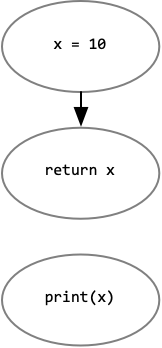

- The print statement is unreachable because execution terminates at the `return` statement  


### CFG basic use #2: Inspecting execution paths

- The edges of a CFG allow us to inspect how execution can move between basic blocks

- For a given block, we can identify:
  - its **successors**: blocks that may execute immediately afterwards
  - its **predecessors**: blocks that may execute immediately before it

- A **path** in a CFG is a sequence of connected blocks representing a possible progression of execution

- Inspecting paths helps us understand the different ways a program can execute:
  - identify the different outcomes of conditional statements
  - determine which sequences of statements may execute together
  - identify execution scenarios that should be covered by tests

- In larger programs, the number of possible paths can grow rapidly, making exhaustive path analysis impractical

### ✏️ Inspecting execution paths with a CFG

- Consider the following program and its CFG:

  ```c
  if (a) {
      if (b) {
          print(x);
      }
  }
  return 1;
  ```

  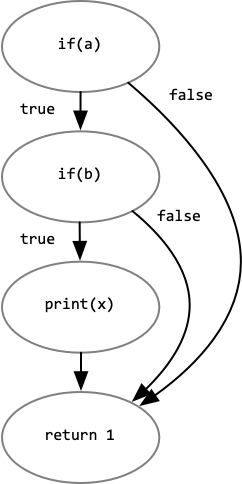


- The CFG represents three possible paths through the conditional structure:
  1. `a` is false
  2. `a` is true and `b` is false
  3. `a` is true and `b` is true


### CFG basic use #3: Recognizing loops

- A loop can be recognized in a CFG by the presence of a **cycle**:
  - A sequence of edges that leads back to a previously visited block

- An edge that returns to the block controlling the loop is called a **back edge**

- The block to which the back edge returns is the **loop header**

- Identifying loops helps us understand program behaviour and provides a starting point for further analyses, including termination analysis

### ✏️ Recognizing loops with a CFG

- Consider the following program and its CFG, with a loop containing a conditional `break`:

  ```c
  i = 0;
  while (i < n) {
      if (i == target)
          break;
      i = i + 1;
  }
  return i;
  ```

  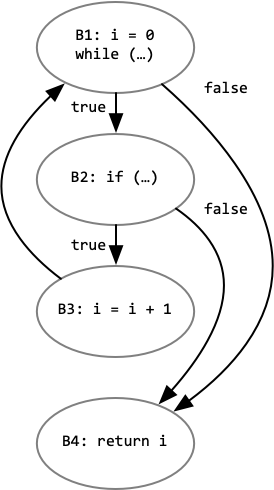

- In the CFG:
  - `B1` is the loop header
  - `B3` connects back to `B1`, forming a cycle
  - The `break` introduces a second loop exit

## Extracting CFGs

- So far, we have constructed and inspected CFGs manually

- In practice, CFGs can be constructed automatically from a representation of the source program, such as an AST

- The extraction process follows the structure of the program:
  - sequential statements are connected in execution order
  - conditional statements introduce branches and merge points
  - loops introduce cycles and exit edges

### CFG extraction with `Lark`

- A parser such as `Lark` can produce a syntax tree that captures the structure of a source program

- We can traverse this tree to construct a CFG

- We can use a `Transformer` to build a CFG compositionally:
  - each statement produces a CFG fragment
  - fragments are connected according to the structure of the program
  - conditional and loop statements introduce branches and cycles

### Representing the CFG in Python

- We can create our own `CFG` class in Python

- Or we can use directly a standard library for graphs, such as `NetworkX`

- We will use `NetworkX` to represent the CFG as a **directed graph** (`DiGraph`)

- This lets us focus on constructing the CFG, while relying on the library for graph operations and visualization

### ✏️ A small language for CFG extraction

- The language includes declarations, assignments, `print`, conditionals and loops

- An `if` has two branches; a `while` has one statement as its body

- A `block` groups multiple statements into a single body

- The grammar deliberately keeps expressions simple
  - Their internal structure is not needed to determine control flow

In [ ]:
grammar = r"""
start: statement+

?statement: declaration
          | assignment
          | print_stmt
          | if_stmt
          | while_stmt
          | block

declaration: "(" "decl" ID TYPE ")"
assignment:  "(" "set" ID expr ")"
print_stmt:  "(" "print" expr ")"
if_stmt:     "(" "if" expr statement statement ")"
while_stmt:  "(" "while" expr statement ")"
block:       "(" "block" statement+ ")"

?expr: "(" OP expr expr ")" -> bin_expr
     | INT                  -> number
     | ID                   -> var

OP: "+" | "-" | "*" | "<" | ">" | "="
TYPE: "int" | "bool"
ID: /[a-zA-Z_][a-zA-Z0-9_]*/
INT: /[0-9]+/

%import common.WS
%ignore WS
"""

#### Example program

- Consider a program with a conditional followed by a loop

- The parser builds a syntax tree;

- The `Transformer` will use its structure to determine how the corresponding CFG fragments are connected

In [ ]:
!pip install lark
!pip install networkx

In [ ]:
from lark import Lark, Transformer
parser = Lark(grammar, parser="lalr")

In [ ]:
program = """
(decl x int)
(set x 10)
(if (> x 0)
    (print x)
    (print 0))
(while (< x 20)
    (block
        (set x (+ x 1))
        (print x)))
(print x)
"""

tree = parser.parse(program)
print(tree.pretty())

start
  declaration
    x
    int
  assignment
    x
    number	10
  if_stmt
    bin_expr
      >
      var	x
      number	0
    print_stmt
      var	x
    print_stmt
      number	0
  while_stmt
    bin_expr
      <
      var	x
      number	20
    block
      assignment
        x
        bin_expr
          +
          var	x
          number	1
      print_stmt
        var	x
  print_stmt
    var	x



### Building CFG fragments

- We represent each part of the program as a **CFG fragment**, consisting of:
  - a directed graph
  - an entry block
  - an exit block

- When two statements execute sequentially, their fragments are connected

- The exit block of the first fragment and the entry block of the next are combined, producing a basic block containing consecutive instructions

- Conditional and loop statements create their own control-flow structure

- The CFG construction focuses on the **control-flow structure** of the program

- Expressions are not represented in detail:
  - assignments and declarations are represented as basic blocks
  - conditions are represented by simplified labels
  - the internal structure of expressions is ignored


In [ ]:
import networkx as nx

In [ ]:
class CFGFragment:
    """A CFG fragment with an entry, an exit and a graph."""

    def __init__(self, entry, exit, graph):
        self.entry = entry
        self.exit = exit
        self.graph = graph

    def merge(self, fragment):
        """Append another fragment, merging consecutive basic blocks."""

        graph = nx.compose(self.graph, fragment.graph)

        previous = self.exit
        following = fragment.entry

        # Merge only ordinary basic blocks.
        if (graph.nodes[previous]["type"] == "basic" and graph.nodes[following]["type"] == "basic"):

            graph.add_edge(previous, following)

            previous_label = graph.nodes[previous]["label"]
            following_label = graph.nodes[following]["label"]

            nx.contracted_nodes(graph, previous, following, self_loops=False, copy=False, store_contraction_as=None)

            graph.nodes[previous]["label"] = (previous_label + "\\n" + following_label)

            self.exit = (previous if fragment.exit == following else fragment.exit)

        else:
            # Preserve control-flow nodes.
            graph.add_edge(previous, following)
            self.exit = fragment.exit

        self.graph = graph

In [ ]:
from lark import Lark, Transformer

class CFGTransformer(Transformer):
    """Build CFG fragments from the syntax tree."""

    def __init__(self):
        super().__init__()
        self.counter = 0

    def new_block(self, label, block_type="basic"):
        """Create a fragment containing one CFG node."""

        name = f"B{self.counter}"
        self.counter += 1

        graph = nx.DiGraph()
        graph.add_node(name, label=f"{name}\\n{label}", type=block_type)

        return CFGFragment(name, name, graph)

    def sequence(self, fragments):
        """Connect fragments in source order."""

        result = fragments[0]

        for fragment in fragments[1:]:
            result.merge(fragment)

        return result

    def start(self, items):
        return self.sequence(items)

    def block(self, items):
        return self.sequence(items)

    def declaration(self, items):
        name, type_ = items
        return self.new_block(f"decl {name}: {type_}")

    def assignment(self, items):
        name, _ = items
        return self.new_block(f"set {name}")

    def print_stmt(self, items):
        return self.new_block("print")

    def if_stmt(self, items):
        """Build a conditional with two branches and a join."""

        condition = self.new_block("if ...", "condition")
        then_branch, else_branch = items[1], items[2]
        join = self.new_block("if join")

        graph = nx.compose_all([condition.graph, then_branch.graph, else_branch.graph, join.graph])

        graph.add_edge(condition.exit, then_branch.entry, branch="true")
        graph.add_edge(condition.exit, else_branch.entry, branch="false")

        graph.add_edge(then_branch.exit, join.entry)
        graph.add_edge(else_branch.exit, join.entry)

        return CFGFragment(condition.entry, join.exit, graph)

    def while_stmt(self, items):
        """Build a loop with a condition, back edge and exit."""

        condition = self.new_block("while ...", "condition")
        body = items[1]
        after_loop = self.new_block("loop exit")

        graph = nx.compose_all([condition.graph, body.graph, after_loop.graph])

        graph.add_edge(condition.exit, body.entry, branch="true")
        graph.add_edge(body.exit, condition.entry)
        graph.add_edge(condition.exit, after_loop.entry, branch="false")

        return CFGFragment(condition.entry, after_loop.exit, graph)

### Extracting and visualizing the CFG

- Applying the transformer constructs a CFG from the syntax tree

- The graph makes the branches, merge points and loop back edge explicit

- The node labels show the statements grouped into basic blocks

- We can use `pydot` and `graphviz` for graph visualization


In [ ]:
!apt-get -qq install graphviz > /dev/null
!pip install graphviz pydot

In [ ]:
from networkx.drawing.nx_pydot import to_pydot
from graphviz import Source

cfg = CFGTransformer().transform(tree).graph

Source(to_pydot(cfg).to_string())


NameError: name 'tree' is not defined

## Data-flow graphs

- While CFGs represent the possible flow of execution, **Data-Flow Graphs (DFGs)** represent dependencies between computations

- A DFG makes explicit how values are produced and consumed:
  - which computations produce values
  - which computations use those values
  - how information flows between computations
  
- DFGs are useful for several program analysis tasks:
  - **Reaching definitions**: determine which definitions may reach a use
  - **Constant propagation**: determine whether a variable has a known value
  - **Dead code detection**: identify computations whose results are never used
  - **Data-dependence-based slicing**: identify computations that contribute to a particular result

- We will focus on data dependencies arising from variable definitions and uses

### Types of data dependencies

- Statements in a program may depend on one another:
  - A statement may use a value computed by another statement
  - A statement may read a value before it is overwritten
  - Multiple statements may write to the same variable

- These relationships are known as **data dependencies**

- Data dependencies are important for understanding program behaviour and determining which statements can be safely reordered

- Three fundamental types can be distinguished:
  - **True (flow) dependence**: a statement produces a value
    consumed by a subsequent statement
  - **Anti-dependence**: a statement reads a value before a
    subsequent statement overwrites it
  - **Output dependence**: two statements write to the same
    variable

- True dependencies represent value flow, whereas anti- and
  output-dependencies impose ordering constraints

- These distinctions are particularly relevant to program
  transformations and instruction scheduling

### ✏️ Data dependencies

#### True (flow) dependence

  ```c
  S1: a = x + 1;
  S2: b = a * 2;
  ```

  - `S1` defines `a`, which is subsequently used by `S2`
  - The value produced by `S1` flows into `S2`
  - `S2` cannot execute before `S1`

#### Anti-dependence

  ```c
  S1: b = a + 1;
  S2: a = x * 2;
  ```

- `S1` reads the current value of `a`
- `S2` subsequently overwrites `a`
- Moving `S2` before `S1` would change the value read by `S1`

#### Output dependence

  ```c
  S1: a = x + 1;
  S2: a = y * 2;
  ```

- Both statements define `a`
- The second definition overwrites the value produced by the first
- Reordering the statements would change the final value of `a`

### From dependencies to DFGs

- Data dependencies can be represented explicitly as relationships
  between program statements

- In particular, **true dependencies** establish which definitions provide the values consumed by subsequent uses

- By representing statements as nodes and true dependencies as directed edges, we obtain a DFG

- A DFG makes the flow of values through a program explicit, independently of the textual ordering of statements

### DFG definition and concepts

- A **Data-Flow Graph (DFG)** is a directed graph where:
  - **Nodes** represent computations, such as assignments or expressions
  - **Edges** represent data dependencies between computations

- A **data dependency** exists when a computation uses a value produced by another computation

- To identify data dependencies, we need to distinguish:
  - **Definitions**: statements where variables receive values
  - **Uses**: expressions or statements where variables are read

- A use may depend on one or more definitions:
  - A definition may reach a use if the value it assigns can be used there, without being overwritten along the way
  - When control-flow paths merge, multiple definitions may reach the same use

### ✏️ Constructing a DFG

- Consider the following C program, assuming that `x` is an input parameter of the function

  ```c
  int y = 0;
  if (x > 0) {
      y = y + 1;
  } else {
      y = y - 1;
  }
  while (y < 5) {
      y = y + 2;
  }
  return y;
  ```

- We start from the basic blocks of its CFG:

  ```c
  B1: y = 0
      if (x > 0) goto B2 else B3

  B2: y = y + 1
      goto B4

  B3: y = y - 1
      goto B4

  B4: while (y < 5) goto B5 else B6

  B5: y = y + 2
      goto B4

  B6: return y
  ```

- For each block, we identify the variables it defines and uses

  | Block | Def | Use |
  |-------|-----|-----|
  | `B1`  | `y` | `x` |   
  | `B2`  | `y` | `y` |   
  | `B3`  | `y` | `y` |   
  | `B4`  |     | `y` |   
  | `B5`  | `y` | `y` |   
  | `B6`  |     | `y` |   

- We then determine which definitions may reach each use, taking the possible control-flow paths into account

- To distinguish different definitions of the same variable, we give each definition a distinct version

  | Block | Definition | Reaching definitions at uses |
  |-------|------------|-------------------------------|
  | `B1`  | `y₁`       | `x?`                          |
  | `B2`  | `y₂`       | `y₁`                          |
  | `B3`  | `y₃`       | `y₁`                          |
  | `B4`  |            | `y₂, y₃, y₄`                  |
  | `B5`  | `y₄`       | `y₂, y₃, y₄`                  |
  | `B6`  |            | `y₂, y₃, y₄`                  |

- Notice that:
  - The definitions `y₂` and `y₃` may both reach the use in condition in `B4`, depending on which branch was taken
  - The definition `y₄` may reach the use in condition in `B4` in subsequent loop iterations
  - The same definitions may reach the use return statement in `B6`, depending on how the loop executes

- The resulting DFG makes these data dependencies explicit:

  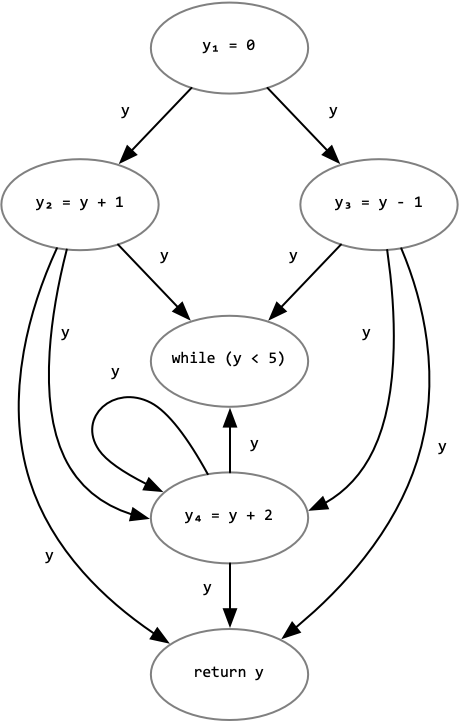

### DFG basic use #1: Reaching definitions

- **Reaching definitions analysis** determines which definitions of a variable may reach a particular use

- A definition reaches a use if there is a possible execution path from the definition to the use along which the variable is not redefined

- This analysis must take control flow into account:
  - different branches may introduce different definitions
  - definitions may reach uses after branches merge
  - loops may cause definitions from previous iterations to reach later uses

- Reaching definitions is a fundamental analysis in its own right

- It also provides the information needed to establish data dependencies and form the basis for other analyses, such as constant propagation

### ✏️ Reaching definitions with a DFG

- Consider the following program:

  ```c
  x = 1;
  if (condition) {
      x = 2;
  }
  print(x);
  ```

- There are two definitions of `x`:
- `x₁ = 1`
- `x₂ = 2`

  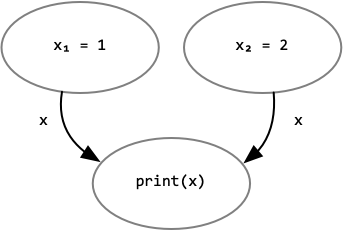


- At the `print(x)` statement, both definitions may reach the use:
  - if `condition` is false, the value comes from `x₁`
  - if `condition` is true, the value comes from `x₂`

- Therefore, the use of `x` in `print(x)` depends on both definitions

- The CFG captures the possible execution paths, while the DFG makes these data dependencies explicit

### DFG basic use #2: Constant propagation

- **Constant propagation** determines whether variables have constant values at particular program points

- It uses information about the possible values of variables:
  - If all possible values are the same constant, the variable has that constant value
  - If different values are possible, the variable cannot be considered constant

- At control-flow merge points, the values from different paths must be considered

- Loops may require repeated analysis until the propagated values stabilize

- Constant propagation can support further simplifications, such as constant folding

### ✏️ Constant propagation with a DFG

- Consider the following program:

  ```c
  x = 1;
  if (flag) {
      printf("true");
      y = x;
  } else {
      printf("false");
      y = x;
  }
  print(y + 2);
  ```

- We can propagate the constant value of `x` to both assignments to `y`

- At the merge point, both possible definitions of `y` assign the same constant value, so `y` is still known to be `1`

- We can consequently simplify the final expression:

  ```c
  print(3);
  ```

### DFG basic use #3: Dead code detection

- **Dead code** is code whose execution does not contribute to the program's observable behaviour

- An assignment is **dead** if its computed value is never used and removing it does not change the program's observable behaviour

- In particular, an assignment with side effects cannot generally be removed merely because its result is unused

- A statement can be reachable in the CFG but still be dead from a data-flow perspective

- Detecting dead assignments can support code simplification and warnings

### ✏️ Example: Dead code detection with a DFG

- Consider the following program:

  ```c
  int y = 4;
  int a = y * 2;
  int b = 3;
  print(b);
  ```

- The assignment to `a` is reachable, but its computed value is never used

  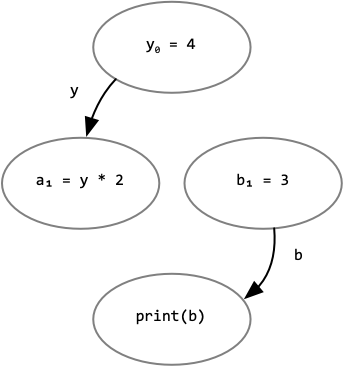

- Since the expression has no side effects, the assignment can be
  removed without changing the program's observable behaviour

- The initialization of `y` is also unnecessary once the assignment
  to `a` is removed

- The resulting program is:
  
  ```c
  int b = 3;
  print(b);
  ```

## Extracting DFGs

- So far, we have constructed and inspected DFGs manually

- In practice, DFGs can be constructed automatically from a representation of the source program, such as the AST

- The extraction process involves:
  - identifying **definitions** and **uses** in the program
  - determining which definitions may reach each use
  - connecting definitions to the corresponding uses

- We will first consider a simple case, where statements execute sequentially and each use has a single preceding definition

### DFG extraction with `Lark`

- `Lark` produces a syntax tree that captures the structure of a source program

- We can traverse this tree to identify definitions and uses, and construct a DFG

- In this example, we use a `Transformer` to process the syntax tree:
  - assignment statements introduce definitions
  - expressions contain uses of variables
  - each use is connected to the preceding definition of that variable

- We start with a simple sequential program, leaving branches and loops for more advanced data-flow analysis

### Representing the DFG in Python

- As with CFGs, we can use [`NetworkX`](https://networkx.org/) to represent the DFG as a **directed graph** (`DiGraph`):
  - nodes represent statements or computations
  - directed edges represent data dependencies
  - edge attributes can identify the variable responsible for each dependency

- We can reuse the graph visualization infrastructure introduced for CFGs

- This allows us to focus on identifying data dependencies, while relying on the graph library for representation and visualization

### ✏️ A small language for DFG extraction

- Let us use a subset of the language defined above for CFGs

- Simplifying assumption: statements execute *sequentially*, without branches or loops

  - We can track the most recent definition of each variable as we traverse the statements

- In programs with branches or loops, several definitions may reach the same use
  - Handling these cases requires **reaching-definitions analysis** over the CFG

- The simplified `Transformer` therefore constructs a DFG using a single preceding definition for each variable, rather than computing all possible reaching definitions

In [ ]:
program = """
(decl x int)
(decl y int)
(decl z int)
(set x 10)
(set y (+ x 5))
(set y (* y x))
(set z (* y y))
(print y)
"""

tree = parser.parse(program)
print(tree.pretty())

start
  declaration
    x
    int
  declaration
    y
    int
  declaration
    z
    int
  assignment
    x
    number	10
  assignment
    y
    bin_expr
      +
      var	x
      number	5
  assignment
    y
    bin_expr
      *
      var	y
      var	x
  assignment
    z
    bin_expr
      *
      var	y
      var	y
  print_stmt
    var	y



In [ ]:
class DFGTransformer(Transformer):
    """Build a DFG for a sequential program."""

    def __init__(self):
        super().__init__()
        self.graph = nx.DiGraph()
        self.last_definition = {}
        self.counter = 0

    def add_statement(self, label, uses, definition=None):
        """Create a node and connect it to the definitions of its uses."""
        self.counter += 1
        node = f"S{self.counter}"
        self.graph.add_node(node, label=label)

        for variable in uses:
            if variable in self.last_definition:
                predecessor = self.last_definition[variable]
                self.graph.add_edge(
                    predecessor, node, label=variable
                )

        if definition is not None:
            self.last_definition[definition] = node

    # Expressions return the set of variables they use.
    def var(self, items):
        return {str(items[0])}

    def number(self, items):
        return set()

    def bin_expr(self, items):
        return items[1] | items[2]

    # Statements contribute nodes and dependencies.
    def declaration(self, items):
        pass

    def assignment(self, items):
        name, uses = items
        self.add_statement(
            f"{name} = ...",
            uses,
            definition=str(name)
        )

    def print_stmt(self, items):
        uses = items[0]
        self.add_statement("print(...)", uses)

    def start(self, items):
        return self.graph

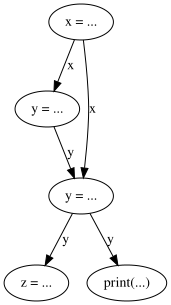

In [ ]:
dfg = DFGTransformer().transform(tree)

Source(to_pydot(dfg).to_string())

## Program dependence graphs

- A **Program Dependence Graph (PDG)** combines data and control dependencies in a single graph

- It contains:
  - **Data-dependence edges**, connecting computations that produce and consume values
  - **Control-dependence edges**, connecting conditions to statements whose execution they determine

- By representing both kinds of dependencies, a PDG provides a more complete view of how statements influence one another

- A PDG combines data and control dependencies, supporting analyses and transformations that require understanding both value flow and execution conditions

- For example, it can support:
  - **Program slicing**: identify computations and control decisions that may influence a result
  - **Control-flow simplification**: use known values to evaluate conditions and identify unreachable branches
  - **Dead code elimination**: identify computations or branches that no longer contribute to observable behaviour

### ✏️ Program dependence graph

- Consider the following program:

  ```c
  x = input();

  if (x > 0) {
      y = x * 2;
  } else {
      y = -x;
  }

  print(y);
  ```

- The PDG represents the dependencies between its statements:
  - The input assignment provides the value of `x` used by the condition and both assignments to `y`
  - The condition determines which assignment to `y` executes
  - The two assignments to `y` provide the value used by `print(y)`

- Data dependencies are represented by solid edges, while control dependencies are represented by dashed edges


  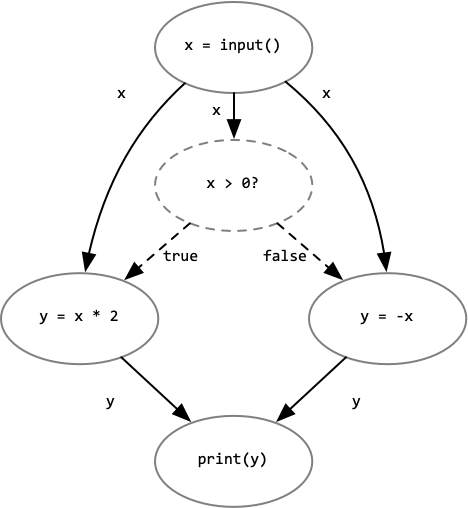

### PDG basic use #1: Simplify control flow

- PDGs can help identify opportunities for simplifying control flow by making explicit the relationship between data dependencies and control dependencies

  - Constant propagation can determine the value of variables used in conditional expressions
  - If a condition is known to be always true or always false, one of its branches is unreachable
  - The PDG makes explicit which statements are control-dependent on that condition, helping identify the code affected by the simplification

- This allows data-flow information to support control-flow simplifications, such as eliminating unreachable branches

### ✏️ Simplify control flow with a PDG

- Consider the following program:

  ```c
  int x = 10;
  int y = x + 1;
  int z;
  if (y > 5) {
      z = y * 2;
  } else {
      z = y * 3;
  }

  print(z);
  ```

- Original PDG

  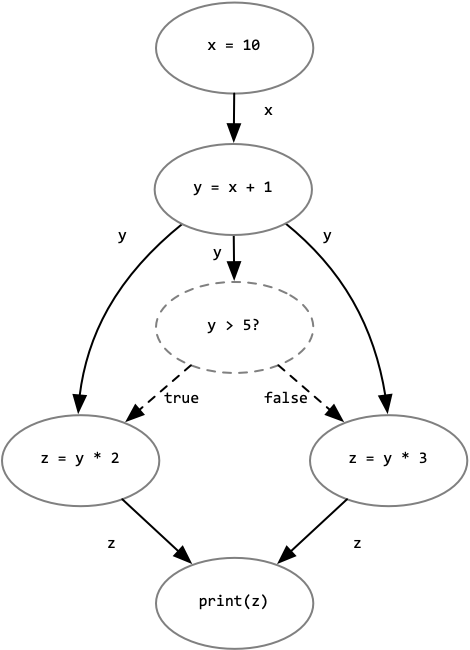

- Constant propagation:
  - Since `x` is known to be `10`, we can substitute this value in its uses, simplifying the assignment to `y`


  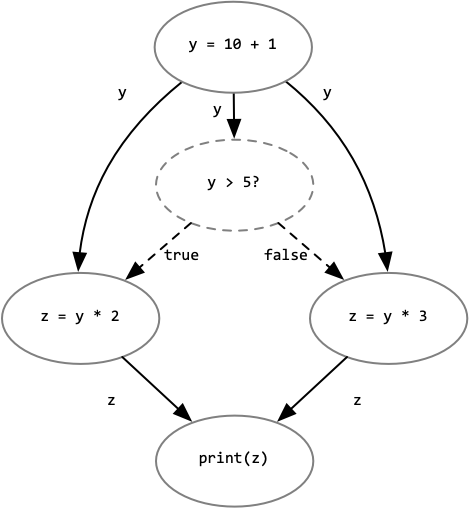

  ```c
  int y = 10 + 1;
  int z;
  if (y > 5) {
      z = y * 2;
  } else {
      z = y * 3;
  }

  print(z);
  ```

- Constant folding and propagation:
  - Constant folding evaluates `10 + 1` to `11`, so we can then propagate the value of `y`


  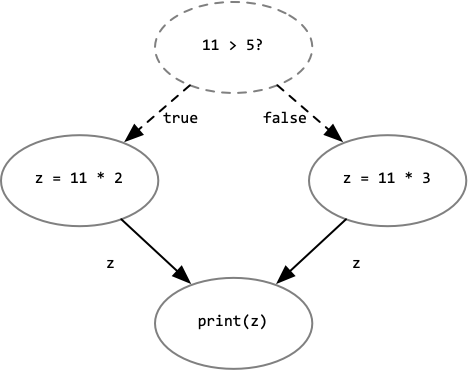
  
  ```c
  int z;
  if (11 > 5) {
      z = 11 * 2;
  } else {
      z = 11 * 3;
  }

  print(z);
  ```

- Constant folding and branch elimination:
  - Constant folding evaluates `11 > 5` to `true` and `11 * 2` to `22`, so the unreachable branch can be eliminated

  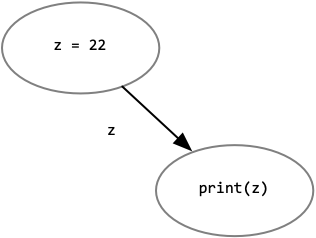

  ```c
  int z;
  z = 22;

  print(z);
  ```

- Constant propagation and dead-code elimination
  - Propagate `z = 22` and eliminate the now-unnecessary initialization and assignment to `z`

  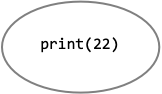

  ```c
  print(22);
  ```

### PDG basic use #2: Program slicing

- A **program slice** with respect to a slicing criterion contains the statements that may influence the value or behaviour of interest

- A **slicing criterion** identifies the program point and, when relevant, the variable whose value we want to analyze

- A **backward slice** can be obtained by following dependence edges backwards from the slicing criterion

- Depending on the representation used:
  - A DFG captures dependencies through data flow
  - A PDG also captures control dependencies

- Since a PDG represents both data and control dependencies, it provides a more complete slice, including conditions that determine whether relevant computations execute

### ✏️ Program slicing with a PDG

- Consider the following program:

  ```c
  x = input();
  y = input();
  x = x * y;
  if (y > 5) {
      y = y * 3;
      x = x * 2;
  }
  print(y);
  ```

-  We are interested in the statements that may influence the value printed by `print(y)`
    - The slicing criterion is the value of `y` at the `print(y)` statement

    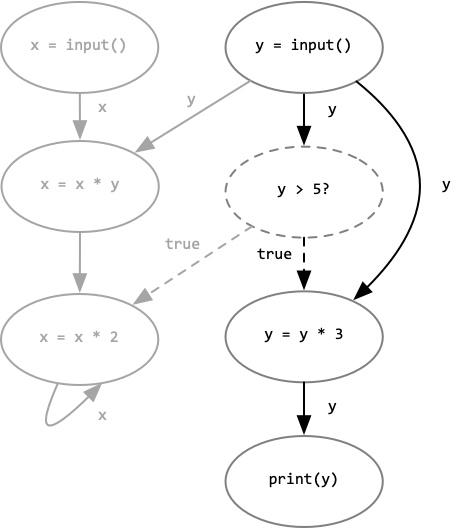

- The **backward slice** with respect to `print(y)` is:

  ```c
  y = input();
  if (y > 5) {
      y = y * 3;
  }
  print(y);
  ```

- Notice that identifying the influence of the condition requires control-dependence information, not just data dependencies

## Interprocedural dependence graphs

- So far, we have considered dependencies within a single function

- **Interprocedural dependence graphs** extend this representation across function boundaries

- They make dependencies between function calls, arguments, parameters and return values explicit

- This allows analyses such as program slicing and impact analysis to consider interactions between functions

- Interprocedural dependencies can involve:
  - actual arguments and formal parameters
  - function calls and return values
  - dependencies propagated across function boundaries

# 8.3 Static Program Analysis

- The goal of *static analysis* is to learn as much as we can from a program **before** executing it

- We want to answer questions like:
  - Is this branch reachable?
  - Does this variable get used uninitialized?
  - Can user input reach this sensitive function?
  - What types can this expression have?
  - Is this loop guaranteed to terminate?
  - Which parts of the program can be affected by my change?

- These questions arise in activities prior to running a program:
  - IDEs/language servers (autocomplete, refactorings, diagnostics, ...)
  - compilers (optimizations, code generation, ...)
  - security tools (taint analysis, vulnerability detection, ...)
  - verification tools (prove safety properties, termination, ...)
  - Software quality metrics and CI  (cyclomatic complexity, maintainability indices, ...)

## Static vs. Dynamic analysis

- Two distinct, but complementary, approaches to program analysis

- A trade-off between **coverage** (how many behaviors are considered) and **precision** (how exact the conclusions are)

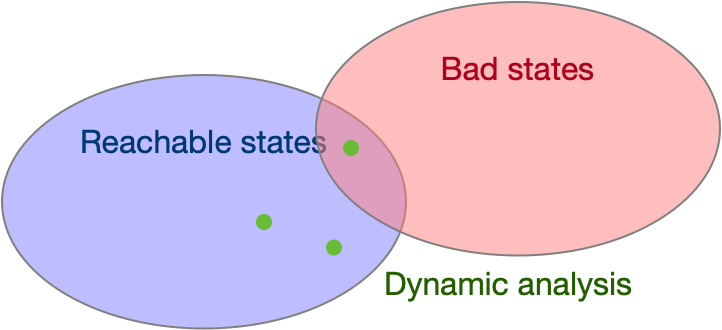
<br/>
<br/>
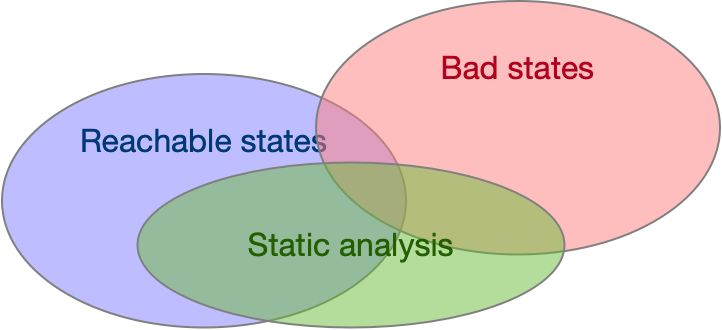

### Dynamic analysis
  - Observes actual executions of a program (concrete inputs → concrete behaviors)
  
  - *Examples*:
    - Profiling
    - Tracing / instrumentation
    - Test runs / fuzzing
    - Runtime bounds checks
    - Dynamic taint tracking

  - **Advantages**:
    - Precise for observed executions
    - No need for abstract approximation

  - **Limitations**:
    - Only covers the behaviors you actually witness
    - Hard or impossible to explore all paths (exponential path explosion)
    - Not suitable for early tooling analysis


### Static analysis

  - Reasons about all possible executions without running the program
  - Operates on models of program behavior: CFGs, DFGs, PDGs, ASTs, types, and other IRs

  - *Examples*:
    - type checking
    - reachability
    - liveness / constant propagation
    - taint analysis
    - race condition detection
    - security policy checks
    - termination/complexity

  - **Advantages**:
    - Can cover all paths, including rare or untested ones
    - Works even on incomplete or partially written programs
    - Enables early detection and tooling

  - **Limitations**:
    - Impossible to be both *sound* (never misses errors) and *complete* (never produces false alarms) because of undecidability
    - Therefore, static analysis must *approximate* program behavior


## A Brief Historical Note

- **1960s–70s**: Static analysis originates in compiler optimizations

- **1970s**: Formal foundations appear — Hoare logic and Abstract Interpretation (Cousot & Cousot, 1977)

- **1980s–2000s**: Analyses expand into verification, security, and software quality tools

- **2010s–present**: Faster hardware enables interactive analysis in IDEs and language servers

- **Today**: Static analysis spans quick IDE hints to full formal verification

## Why Approximations?

- Programs are infinite; static analyses must be finite

- Consider trying to know: *Is variable `x` always non-negative?*
  - Dynamic analysis can run many tests, but cannot be exhaustive
  - Static analysis must cover all possible inputs + all possible paths
  - It cannot track exact runtime values
  - It must use finite abstractions

- In general, precise reasoning about interesting properties is *undecidable*

- Many seemingly simple questions reduce to the Halting Problem:
  - Does this loop terminate for all inputs?
  - Is this branch ever taken?
  - Will this pointer ever be null?

- If we could solve them exactly, we could decide whether arbitrary programs halt

- Therefore analyses:
  - cannot track exact values for unbounded data
  - cannot analyze unbounded loops exactly
  - cannot explore infinite state spaces
  - must use finite abstractions (coarse summaries)

- Undecidability forces analyses to choose:
  - give up soundness → miss some bugs
  - give up completeness → raise false alarms
  - give up scalability → too slow to be useful
  - no tool gets all three

## Over-Approximation and Under-Approximation

- The goal is to obtain safe, computable abstractions of program behaviours

- Two fundamental kinds are over-approximation and under-approximation

###  Over-approximation
  - Sound, conservative analysis
  - Safe, includes everything that *might* happen
  - Used in verification tools, type checkers, security analyses
  - Never misses real issues, but may report *false positives*
  - *Example:* nullness checker warns even if a null path is impossible but not provably so

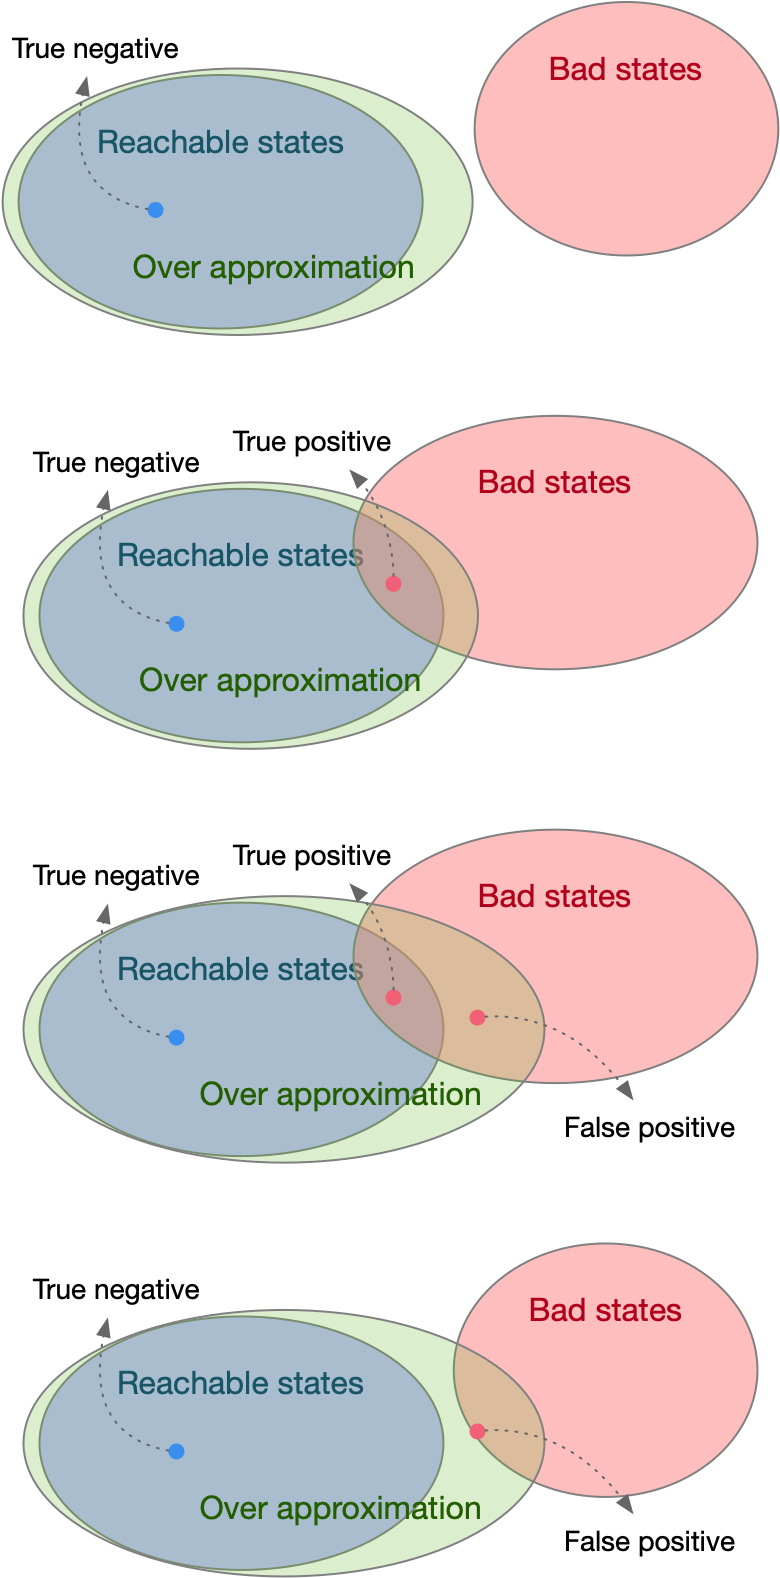

### Under-approximation
  - Complete, optimistic analysis
  - Only consider what we can *prove* happens
  - No false positives, but false negatives
  - Used for bug finding where false alarms are more critical than missing bugs
  - Encourages exploration of feasible bugs

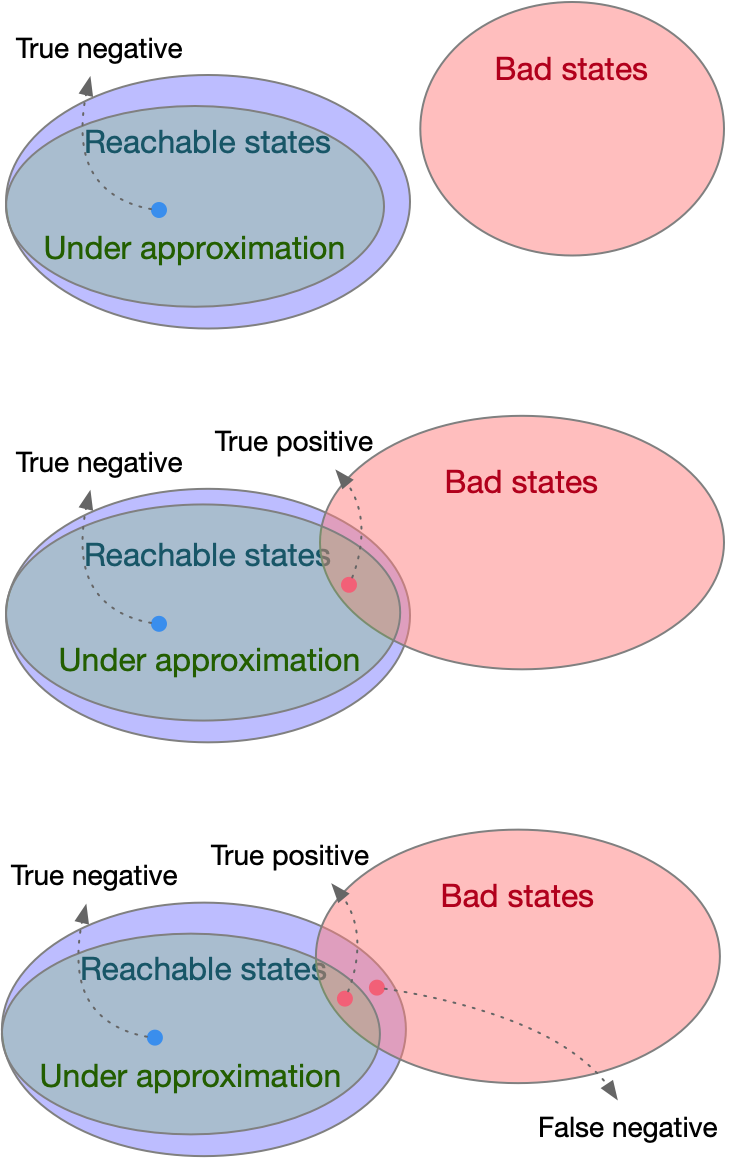

Most real tools fall somewhere in between:
  - heuristics, partial path exploration, mixed static + dynamic

## Getting back to IRs

- CFGs
  - Over-approximate execution order
  - E.g., both branches of an `if` may be explored

- DFGs
  - Over-approximate data dependence
  - E.g., multiple definitions may reach one use

- Static analyses
  - Propagate abstract states over IRs
  - Flow abstract states along CFG edges
  - Use DFG edges to relate definitions and uses
  - Approximate until states stabilize (fixed point)


## The Landscape of Static Analyses

There is a broad spectrum of techniques, from faster and lightweight to heavy and highly complex.

### Flow analyses (CFG/DFG-based)

- Classical dataflow over control-flow graphs
  - Liveness, reaching definitions
  - Constant propagation
  - Dead code detection
  - Taint analysis (as a flow problem)

- These are the foundational, compiler-style analyses

### Type and effect systems

- Reason about the shape (type) and behavior (effect) of values
  - Type checking, subtyping, generics
  - Mutation, purity, side effects
  - Exceptions, control-flow effects

- Fast, compositional, and suitable for IDEs and compilers

### Alias, pointer, and memory analyses

- Determine how memory is referenced, shared, and flows through a program
  - Pointer/alias analysis
  - Escape analysis
  - Region/ownership inference

- Supports optimizations, safety checks, and concurrency tooling

### Abstract interpretation

- A unifying mathematical framework for approximating program behavior
  - Interval/constant domains
  - Nullness/shape domains
  - Range and overflow checks
  - General fixed-point computations over IRs

- Provides scalable, sound over-approximations

### Symbolic reasoning & Formal verification

- Analyses powered by logic and automated reasoning
  - Symbolic execution (under-approximation)
  - Model checking (finite-state over-approximation)
  - Deductive verification (Hoare logic, SMT/theorem proving)

- Used in security, safety-critical systems, and high-assurance software

## Deeper dive into abstract Interpretation

- Abstract interpretation is the general theory that explains almost all static analyses:
  - Constant propagation
  - Nullness checkers
  - Interval/numerical analyses
  - Taint analysis
  - Escape / alias analyses
  - Even type systems (seen as abstract interpreters over types)

- It explains:
  - How to design abstractions
  - How to compute fixed points
  - How to enforce soundness
  - Why approximations must exist


### Operationalizing abstract interpretation

- Concrete semantics:
  - The exact meaning of the program
  - Potentially infinite, undecidable to compute

- Abstract domain:
  - A **finite** (or finitely representable) set of properties
  - A lattice, organized by a precision ordering (`≤`)
  - *Examples*: intervals, signs, taint bits, alias sets
  - Each abstract value represents *many* concrete states

- Abstract semantics:
  - Interpret the same program using abstract values
  - Each statement has a transfer function that the abstract state
  - *Example*: `[0, 10] + [1, 1] = [1, 11]`
  - Must be **sound**: abstract result includes all concrete possibilities

- Join operator (`⊔`):
  - Merges information from different paths
  - Ensures **all** possible executions are accounted
  - *Example*: `[0,5] ⊔ [3,10] = [0,10]`

- Fixed point:
  - Propagate abstract states along the CFG
  - Repeatedly apply abstract transfer functions
  - Stops when states stabilize: `state_new = state_old`
  - Handles loops and recursion

- Widening:
  - Prevents infinite ascending chains in the lattice
  - Detects unbounded growth and forces a jump to a coarse summary
  - *Example*: `[0,10] → [0,11] → [0,12] → [0,+∞]`
  - Guarantees termination of the analysis
  

### Designing abstract domains

#### Example 1: Sign domain

- Represents whether a value is `{−, 0, +}`

- Great for simple reasoning, but too coarse for most programs

#### Example 2: Interval domain

- Values are ranges: `[l, u]`

- Operations propagate bounds: `[l1,u1] + [l2,u2] = [l1+l2, u1+u2]`

- Joins: `[l1,u1] ⊔ [l2,u2] = [min(l1,l2), max(u1,u2)]`

- Can prove:
  - overflow absence
  - array bound safety
  - loop invariants (with widening)

#### Example 3: Taint Domain

- Two-point lattice: `{untainted, tainted}`

- Join: `untainted ⊔ tainted = tainted`

- One of the simplest, most practical domains

## Example

```c
x = input();
if (x < 0)
    x = -x;
y = 0;
while (x < 20) {
    y = y + x;
    x = x + 2;
}
if (y == 30)
    report();
```

### Abstract interpretation
  - Abstract domain: intervals `[l,u]`

  - Initial bounds:
    - `x = [-∞, +∞]` (unknown user input)
    - `y = [0, 0]`

  - After making absolute:
    - `x = [0, +∞]`

  - Loop iteration, condition `x < 20`:
    - Iteration 1:
      - `y = y + x` → `[0,0] + [0,20] = [0,20]`
      - `x = x + 2` → `[0,20] + [2,2] = [2,22]`

   - Iteration 2 (joined with previous states):
     - `x` becomes `[0,22]`
     - `y` becomes `[0,42]`

   - Both eventually widen to `[0, +∞]`

   - More precise variants with bound analysis could instead identify
     - `x ∈ [0, 20]`
     - `y ∈ [0, 200]`

 - Final condition: `y == 30`?
   - It is within the range, so it *may* be reachable

    
### Taint Analysis

 - Abstract domain: {Tainted, Untainted}

   - `x = tainted`
   - after `x = -x`, still tainted
   - all arithmetic keeps taint
   - y becomes tainted in the loop

 - At the end:
   - `y` is tainted
   - `report()` depends on tainted data

 - Tainted input may drive the program into `report()`


## Putting it all together

- You can position all techniques on two axes:

- *Axis 1*: Strength of approximation
  - Under-approximation: symbolic execution, fuzzing
  - Exact (restricted domains): type systems
  - Over-approximation: dataflow, abstract interpretation

- *Axis 2*: IR required
  - AST level (lints, type systems)
  - CFG level (dataflow, taint analysis)
  - SSA / DFG / PDG (pointer analysis, optimizations)
  - Logical models (model checking / SMT)

- The language **grammar** determines the AST, which impacts all subsequent analyses

- If the grammar is ambiguous, overly generic, or poorly structured, the AST becomes unusable for static analysis

- Grammar engineering is the foundation on which IR generation, abstract interpretation, and the entire tooling ecosystem rests


-- nmm, 2026-11-19